
# Chapter 6: Statistical Machine Learning

## Objectives

This chapter explores statistical machine learning algorithms
and compares their predictive performance on the same dataset.

## Learning Outcomes

- Understand different machine learning approaches.
- Compare linear and nonlinear classification methods.
- Understand the role of feature scaling.
- Evaluate models using consistent metrics.
- Interpret model performance and limitations.



## 1. Theoretical Background

Statistical machine learning combines statistical reasoning
and computational algorithms to learn patterns from data.

Different algorithms represent relationships between features
and outcomes in different ways.

1. Logistic Regression estimates class probabilities using a
   logistic function applied to a linear predictor.

2. K-Nearest Neighbors (KNN) predicts a class based on the labels
   of nearby observations in feature space.

3. Decision Trees learn decision rules by recursively splitting
   data according to selected features.

4. Random Forest combines predictions from multiple decision trees
   to reduce dependence on an individual tree.

Model performance depends on the dataset, preprocessing,
hyperparameters, and evaluation procedure.

No algorithm is universally best for every problem.


In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


In [2]:

data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Number of classes:", y.nunique())


Dataset shape: (569, 30)
Number of features: 30
Number of classes: 2


In [3]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)


Training set: (455, 30)
Testing set: (114, 30)



## 2. Classification Algorithms

This experiment compares three algorithms.

Logistic Regression provides a linear decision boundary in the
standard feature space.

KNN is a distance-based method. Its predictions depend on nearby
training observations, so feature scaling is important.

Random Forest combines many decision trees trained using randomized
samples and feature selection. It can model nonlinear relationships
and generally does not require feature standardization.

All three models use the same training and testing split to make
their comparison more consistent.


In [4]:

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
}

print("Models prepared:")
for name in models:
    print("-", name)


Models prepared:
- Logistic Regression
- KNN
- Random Forest


In [5]:

results = []

for name, model in models.items():

    # Train the model
    model.fit(X_train, y_train)

    # Predict the test set
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("Model evaluation results:")
display(results_df.round(4))


Model evaluation results:


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.9825,0.9861,0.9861,0.9861
1,KNN,0.9561,0.9589,0.9722,0.9655
2,Random Forest,0.9561,0.9589,0.9722,0.9655


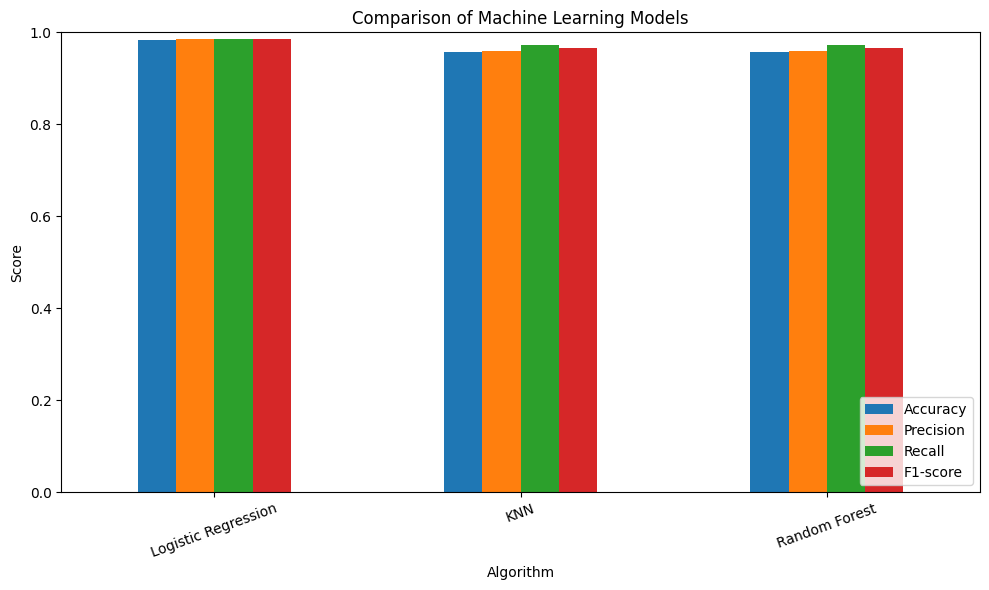

In [6]:

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1)
)

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Algorithm")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [7]:

# Identify the highest F1-score on this test split.
best_model = results_df.loc[
    results_df["F1-score"].idxmax()
]

print("Model with the highest test F1-score:")
print(best_model.to_string())

print(
    "\nNote: This result applies to the current test split "
    "and is not proof that the algorithm is universally best."
)


Model with the highest test F1-score:
Model        Logistic Regression
Accuracy                0.982456
Precision               0.986111
Recall                  0.986111
F1-score                0.986111

Note: This result applies to the current test split and is not proof that the algorithm is universally best.



## 3. Results and Discussion

The comparison evaluates Logistic Regression, KNN, and Random Forest
using the same dataset and testing observations.

Accuracy describes overall correctness. Precision and recall help
explain the types of classification performance, while F1-score
balances precision and recall.

Logistic Regression provides a relatively simple linear model.
KNN relies on distance between observations, and Random Forest
combines multiple decision trees to capture potentially nonlinear
relationships.

The highest score in this experiment identifies the strongest
result under the chosen metric and test split. It does not guarantee
that the same algorithm will perform best on another dataset.

For a more reliable comparison, cross-validation and hyperparameter
tuning should be conducted using training data only. The test set
should be reserved for final evaluation.



## 4. Conclusion

This chapter demonstrates that different machine learning
algorithms learn patterns using different strategies.

Logistic Regression, KNN, and Random Forest were trained and
evaluated using accuracy, precision, recall, and F1-score.

The results illustrate the importance of comparing models with
consistent data splits and suitable evaluation metrics.

Model selection should also consider interpretability, computational
cost, robustness, and the requirements of the application.
